<a href="https://colab.research.google.com/github/agugun/axscnt-notebook/blob/main/Vector_Calculus_Basic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- VERIFYING THE FUNDAMENTAL THEOREM OF LINE INTEGRALS ---
Start Point A: (-2.00, -1.50) -> Z(A) = 0.043937
End Point B:   (1.50, 1.50) -> Z(B) = 0.105399
Direct Potential Difference Z(B) - Z(A): 0.061462
Line Integral of Gradient field:        0.061464
Absolute error:                         1.64e-06
-----------------------------------------------------------


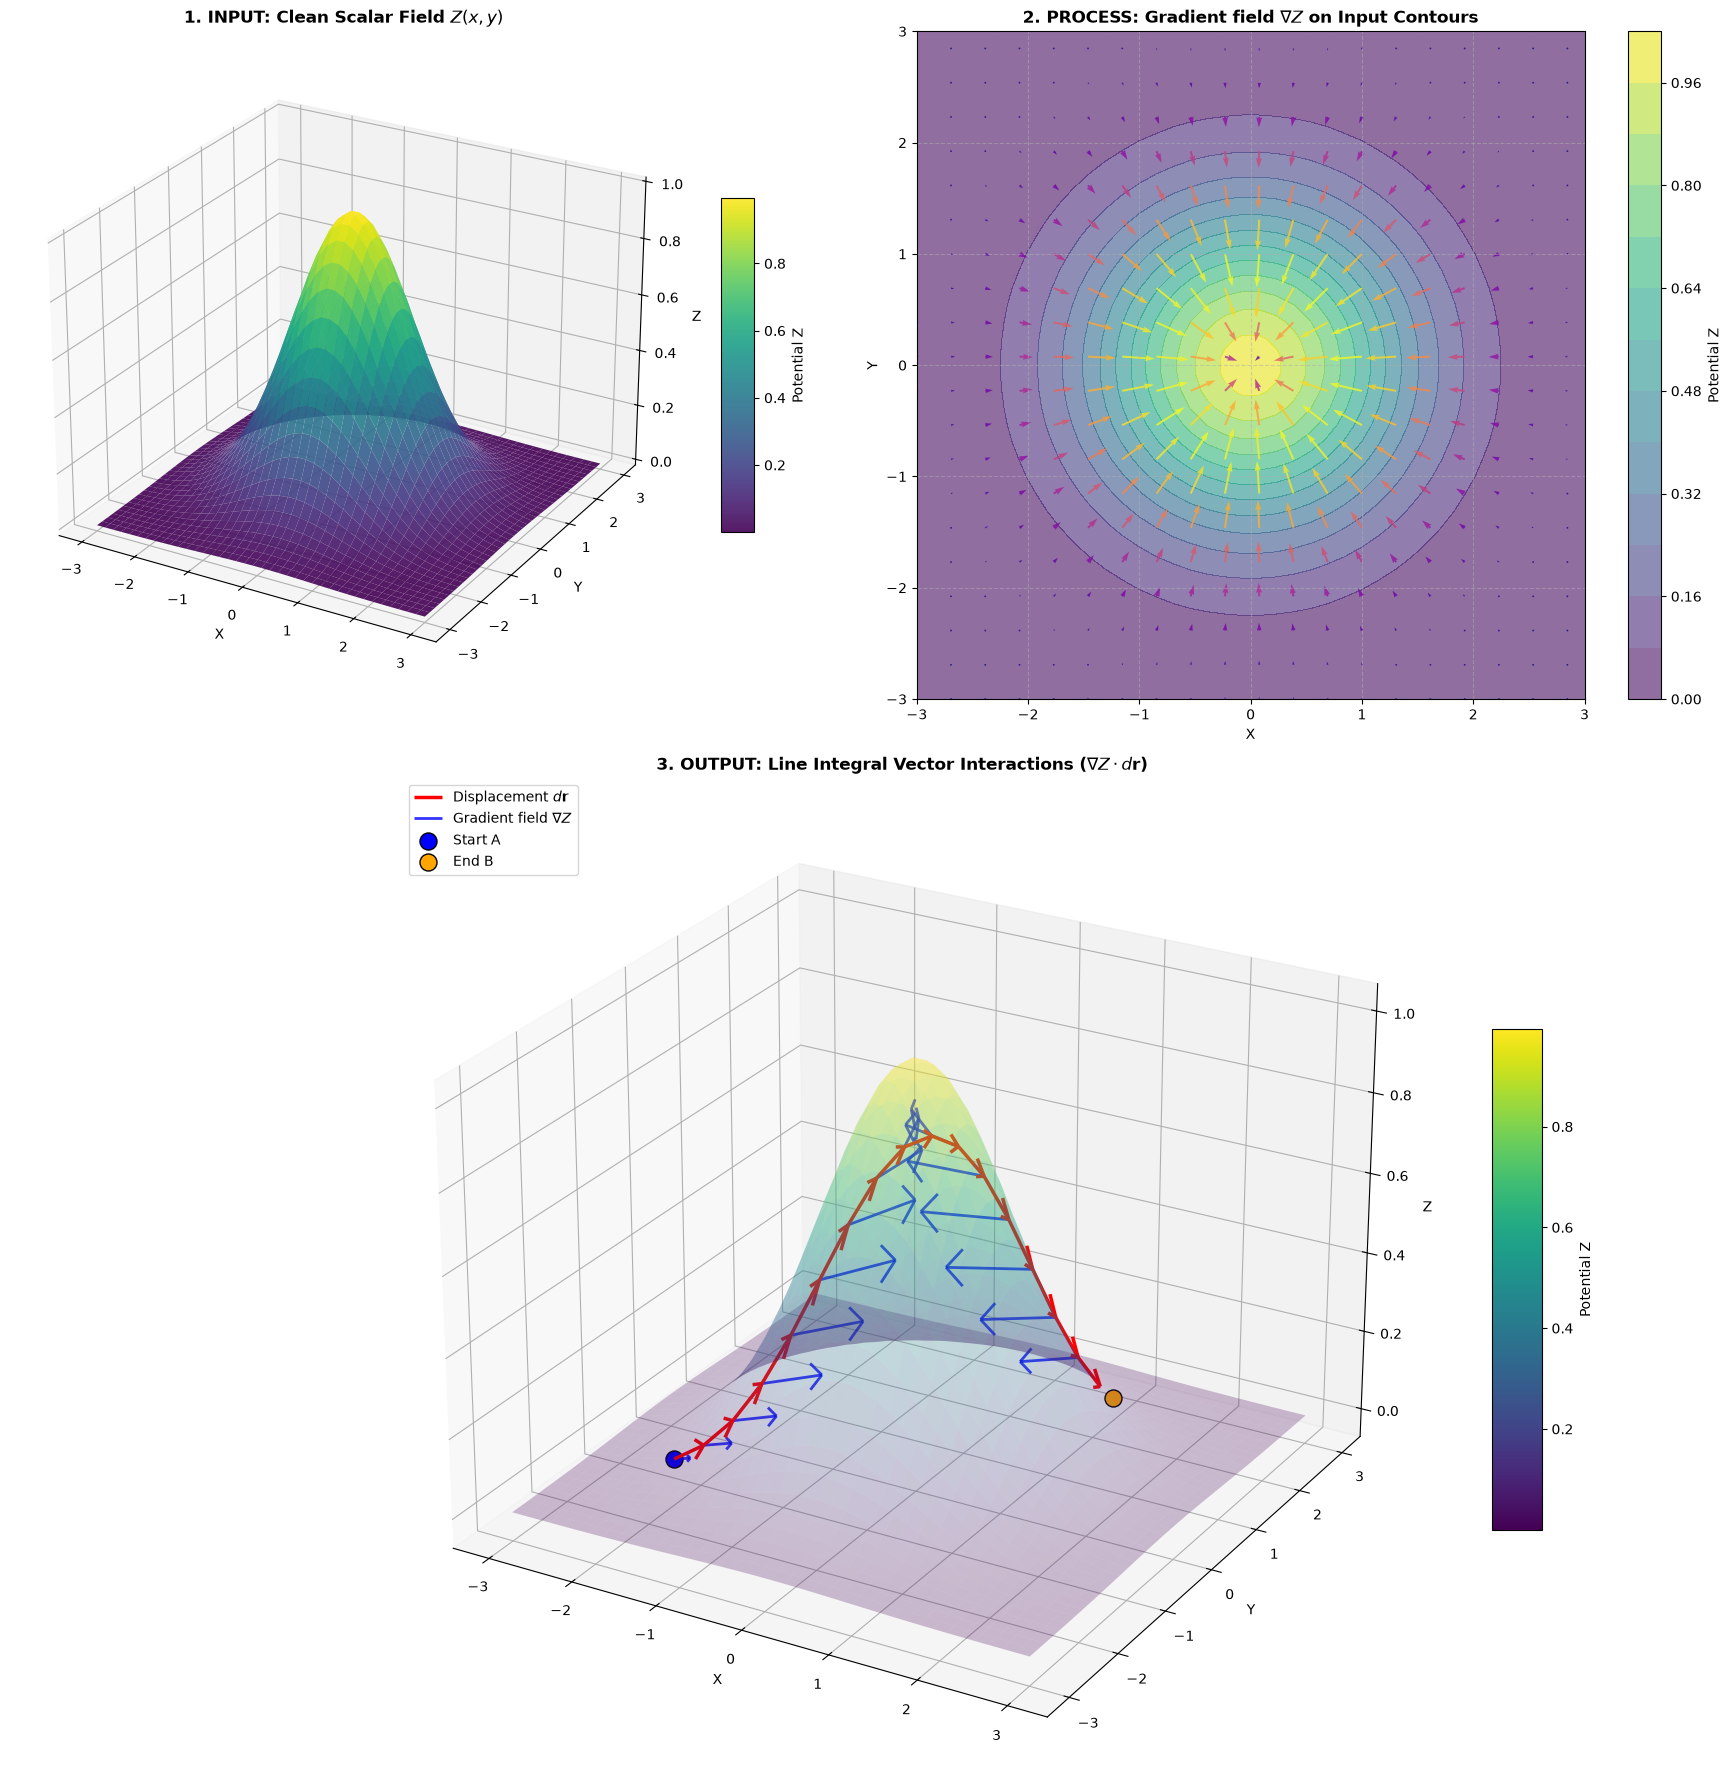

In [47]:
# Connect gradient with line integrals: The Fundamental Theorem of Line Integrals
# Restructured to show Input, Process, and Output with interacting field and displacement vectors

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Define the 2D grid and scalar potential field Z (Gaussian Hill)
x_vals = np.linspace(-3, 3, 40)
y_vals = np.linspace(-3, 3, 40)
X, Y = np.meshgrid(x_vals, y_vals)
Z = np.exp(-(X**2 + Y**2) / 2.0)

# Compute numerical gradient
dZ_dy, dZ_dx = np.gradient(Z, y_vals, x_vals)

# 2. Define a curved parameterized path r(t) = (x(t), y(t))
t = np.linspace(0, 1, 200)
path_x = -2.0 * (1 - t) + 1.5 * t + 0.5 * np.sin(np.pi * t)
path_y = -1.5 * (1 - t) + 1.5 * t - 0.5 * np.sin(np.pi * t)

# Calculate derivatives and evaluate line integral
dt = t[1] - t[0]
dx_dt = np.gradient(path_x, dt)
dy_dt = np.gradient(path_y, dt)
path_Z = np.exp(-(path_x**2 + path_y**2) / 2.0)
path_grad_x = -path_x * path_Z
path_grad_y = -path_y * path_Z

integrand = path_grad_x * dx_dt + path_grad_y * dy_dt
trapezoid_func = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
if trapezoid_func is not None:
    line_integral = trapezoid_func(integrand, t)
else:
    line_integral = np.sum((integrand[:-1] + integrand[1:]) / 2.0) * dt

Z_A = path_Z[0]
Z_B = path_Z[-1]
potential_difference = Z_B - Z_A

print("--- VERIFYING THE FUNDAMENTAL THEOREM OF LINE INTEGRALS ---")
print(f"Start Point A: ({path_x[0]:.2f}, {path_y[0]:.2f}) -> Z(A) = {Z_A:.6f}")
print(f"End Point B:   ({path_x[-1]:.2f}, {path_y[-1]:.2f}) -> Z(B) = {Z_B:.6f}")
print(f"Direct Potential Difference Z(B) - Z(A): {potential_difference:.6f}")
print(f"Line Integral of Gradient field:        {line_integral:.6f}")
print(f"Absolute error:                         {abs(line_integral - potential_difference):.2e}")
print("-----------------------------------------------------------")

# 3. Build a two-row visualization: Input & Process on top, Output across the bottom
fig = plt.figure(figsize=(18, 18))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.5])

# --- Panel 1: INPUT (Clean Scalar Potential Surface) ---
ax1 = fig.add_subplot(gs[0, 0], projection='3d')
surf = ax1.plot_surface(X, Y, Z, cmap='viridis', alpha=0.9, edgecolor='none')
ax1.set_title('1. INPUT: Clean Scalar Field $Z(x, y)$', fontsize=12, fontweight='bold')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.view_init(elev=25, azim=-60)
fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=10, label='Potential Z')

# --- Panel 2: PROCESS (Gradient Overlying Input Potential) ---
ax2 = fig.add_subplot(gs[0, 1])
contours_proc = ax2.contourf(X, Y, Z, levels=15, cmap='viridis', alpha=0.6)
step = 2
magnitude = np.hypot(dZ_dx, dZ_dy)
quiv_proc = ax2.quiver(X[::step, ::step], Y[::step, ::step], dZ_dx[::step, ::step], dZ_dy[::step, ::step],
                       magnitude[::step, ::step], cmap='plasma', scale_units='xy', scale=2, width=0.003, alpha=0.8)
ax2.set_title('2. PROCESS: Gradient field $\\nabla Z$ on Input Contours', fontsize=12, fontweight='bold')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_aspect('equal')
ax2.grid(True, linestyle='--', alpha=0.5)
fig.colorbar(contours_proc, ax=ax2, label='Potential Z')

# --- Panel 3: OUTPUT (3D Path Integration showing F and dr Vectors) ---
ax3 = fig.add_subplot(gs[1, :], projection='3d')
surf_out = ax3.plot_surface(X, Y, Z, cmap='viridis', alpha=0.25, edgecolor='none')

# Subsample the path to show clear, non-overlapping vector arrows
step_idx = 12
px_coarse = path_x[::step_idx]
py_coarse = path_y[::step_idx]
pz_coarse = path_Z[::step_idx]

# 1. Displacement vectors along path C (dr_x, dr_y, dr_z)
dr_x = np.diff(px_coarse)
dr_y = np.diff(py_coarse)
dr_z = np.diff(pz_coarse)

# 2. Field vectors (Gradient) evaluated along the path
# Using analytical gradient: grad Z = (-x * Z, -y * Z, -1)
# For 3D visualization, we can show the 2D gradient on the surface or its tangent projection
pg_x = -px_coarse[:-1] * pz_coarse[:-1]
pg_y = -py_coarse[:-1] * pz_coarse[:-1]
pg_z = np.zeros_like(pg_x) # Keep field vectors flat or tangent for visual clarity

# Plot the displacement vectors (dr) in Red
ax3.quiver(px_coarse[:-1], py_coarse[:-1], pz_coarse[:-1],
           dr_x, dr_y, dr_z,
           color='red', arrow_length_ratio=0.3, linewidth=2.5, pivot='tail', label='Displacement $d\\mathbf{r}$')

# Plot the field gradient vectors (F) in Blue/Cyan acting at those same points
scale_factor = 1.5 # Scale up gradient arrows for visibility
ax3.quiver(px_coarse[:-1], py_coarse[:-1], pz_coarse[:-1],
           pg_x * scale_factor, pg_y * scale_factor, pg_z,
           color='blue', arrow_length_ratio=0.2, linewidth=2.0, pivot='tail', alpha=0.8, label='Gradient field $\\nabla Z$')

# Mark 3D endpoints A and B
ax3.scatter([path_x[0]], [path_y[0]], [Z_A], color='blue', s=150, edgecolor='black', zorder=15, label='Start A')
ax3.scatter([path_x[-1]], [path_y[-1]], [Z_B], color='orange', s=150, edgecolor='black', zorder=15, label='End B')

ax3.set_title('3. OUTPUT: Line Integral Vector Interactions ($\\nabla Z \\cdot d\\mathbf{r}$)', fontsize=12, fontweight='bold')
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
ax3.set_zlabel('Z')
ax3.view_init(elev=25, azim=-60)
ax3.set_box_aspect(None, zoom=1.05)
ax3.legend(loc='upper left')
# Opaque colorbar (the surface itself is drawn faint at alpha=0.25)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=surf_out.norm)
fig.colorbar(sm, ax=ax3, shrink=0.5, aspect=10, label='Potential Z')

plt.tight_layout()
plt.show()

--- VERIFYING THE DIVERGENCE THEOREM ---
Region Area Integral ∬ (∇·F) dA:   1.219133
Boundary Flux Integral ∮ (F·n) ds: 1.198408
Absolute error:                    2.07e-02
----------------------------------------


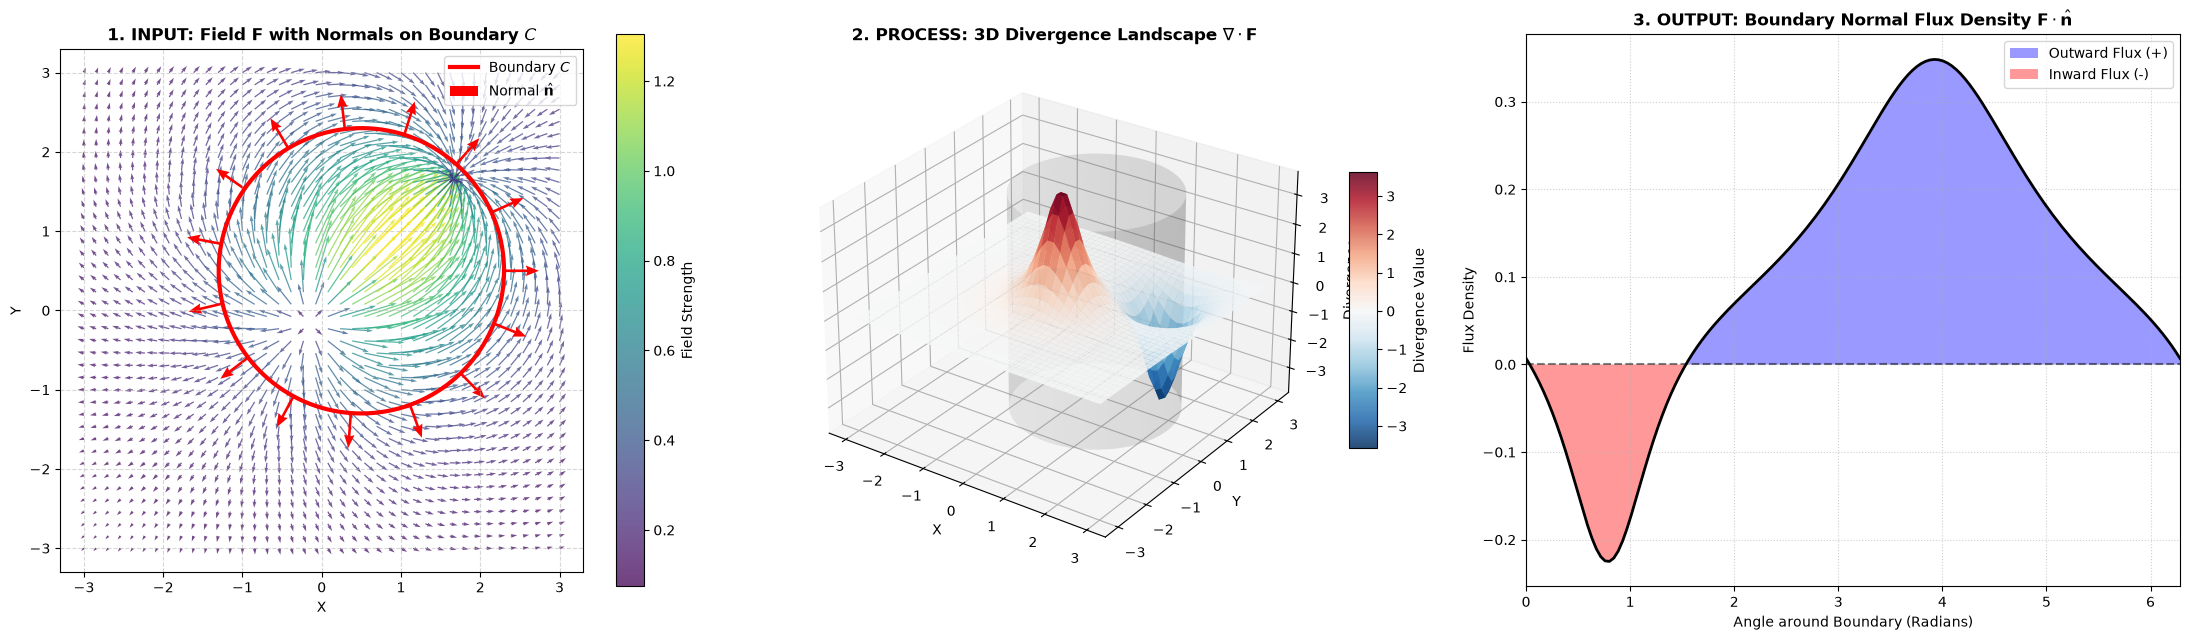

In [48]:
# Connecting Divergence with Volume/Area Integrals (The Divergence Theorem)

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Setup a high-resolution 2D grid
x = np.linspace(-3, 3, 40)
y = np.linspace(-3, 3, 40)
X, Y = np.meshgrid(x, y)

# 2. Define a vector field F with a source at (0, 0) and a sink at (1.5, 1.5)
# This creates clear spatial regions of positive and negative divergence
U = X / (X**2 + Y**2 + 0.5) - (X - 1.5) / ((X - 1.5)**2 + (Y - 1.5)**2 + 0.5)
V = Y / (X**2 + Y**2 + 0.5) - (Y - 1.5) / ((X - 1.5)**2 + (Y - 1.5)**2 + 0.5)

# Calculate divergence: div F = dU/dx + dV/dy
dU_dy, dU_dx = np.gradient(U, y, x)
dV_dy, dV_dx = np.gradient(V, y, x)
divergence_scalar = dU_dx + dV_dy

# 3. Define a circular boundary C of radius R centered at (0.5, 0.5)
# This boundary encapsulates the source and partially includes the sink
R_bound = 1.8
x_center, y_center = 0.5, 0.5
t_bound = np.linspace(0, 2*np.pi, 150)
bound_x = x_center + R_bound * np.cos(t_bound)
bound_y = y_center + R_bound * np.sin(t_bound)

# 4. Integrate Divergence over the circular region (Area Integral)
# We'll mask the grid points to stay inside the circle
mask_inside = (X - x_center)**2 + (Y - y_center)**2 <= R_bound**2
dx_val = x[1] - x[0]
dy_val = y[1] - y[0]
double_integral = np.sum(divergence_scalar[mask_inside]) * dx_val * dy_val

# 5. Integrate flux along the boundary rim (Line Integral of F . n)
dt = t_bound[1] - t_bound[0]
# Parametric derivatives ds/dt
dx_dt = -R_bound * np.sin(t_bound)
dy_dt = R_bound * np.cos(t_bound)
ds = np.sqrt(dx_dt**2 + dy_dt**2) * dt

# Unit normals along boundary (pointing outwards)
nx = np.cos(t_bound)
ny = np.sin(t_bound)

# Interpolate field vectors onto the boundary
bound_U = bound_x / (bound_x**2 + bound_y**2 + 0.5) - (bound_x - 1.5) / ((bound_x - 1.5)**2 + (bound_y - 1.5)**2 + 0.5)
bound_V = bound_y / (bound_x**2 + bound_y**2 + 0.5) - (bound_y - 1.5) / ((bound_x - 1.5)**2 + (bound_y - 1.5)**2 + 0.5)

# Flux integrand: F . n
flux_integrand = bound_U * nx + bound_V * ny
trapezoid_func = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
if trapezoid_func is not None:
    boundary_flux_integral = trapezoid_func(flux_integrand * np.sqrt(dx_dt**2 + dy_dt**2), t_bound)
else:
    boundary_flux_integral = np.sum((flux_integrand[:-1] + flux_integrand[1:]) / 2.0 * np.sqrt(dx_dt[:-1]**2 + dy_dt[:-1]**2)) * dt

print("--- VERIFYING THE DIVERGENCE THEOREM ---")
print(f"Region Area Integral ∬ (∇·F) dA:   {double_integral:.6f}")
print(f"Boundary Flux Integral ∮ (F·n) ds: {boundary_flux_integral:.6f}")
print(f"Absolute error:                    {abs(double_integral - boundary_flux_integral):.2e}")
print("----------------------------------------")

# 6. Plotting the results across a 3-panel visualization
fig = plt.figure(figsize=(22, 6.5))

# --- Panel 1: INPUT (Vector Field & Boundary) ---
ax1 = fig.add_subplot(1, 3, 1)
magnitude = np.hypot(U, V)
quiv = ax1.quiver(X, Y, U, V, magnitude, cmap='viridis', scale=10, alpha=0.75)
ax1.plot(bound_x, bound_y, 'r-', linewidth=3, label='Boundary $C$')

# Plot outward normals at coarse intervals
step = 10
ax1.quiver(bound_x[::step], bound_y[::step], nx[::step], ny[::step],
           color='red', scale=15, width=0.005, headwidth=4, label='Normal $\\hat{\\mathbf{n}}$')

ax1.set_title('1. INPUT: Field $\\mathbf{F}$ with Normals on Boundary $C$', fontsize=12, fontweight='bold')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_aspect('equal')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right')
fig.colorbar(quiv, ax=ax1, label='Field Strength')

# --- Panel 2: PROCESS (Divergence Landscape) ---
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
surf = ax2.plot_surface(X, Y, divergence_scalar, cmap='RdBu_r', edgecolor='none', alpha=0.85)

# Draw bounding cylinder containing the integrated volume/area
t_cyl = np.linspace(0, 2*np.pi, 100)
z_cyl = np.linspace(np.min(divergence_scalar), np.max(divergence_scalar), 10)
Tc, Zc = np.meshgrid(t_cyl, z_cyl)
Xc = x_center + R_bound * np.cos(Tc)
Yc = y_center + R_bound * np.sin(Tc)
ax2.plot_surface(Xc, Yc, Zc, color='gray', alpha=0.15, edgecolor='none')

ax2.set_title('2. PROCESS: 3D Divergence Landscape $\\nabla \\cdot \\mathbf{F}$', fontsize=12, fontweight='bold')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Divergence')
ax2.view_init(elev=28, azim=-55)
fig.colorbar(surf, ax=ax2, shrink=0.5, aspect=10, label='Divergence Value')

# --- Panel 3: OUTPUT (Normal Flux Profile & Total Sum) ---
ax3 = fig.add_subplot(1, 3, 3)
ax3.fill_between(t_bound, flux_integrand, 0, where=(flux_integrand >= 0),
                 facecolor='blue', alpha=0.4, label='Outward Flux (+)')
ax3.fill_between(t_bound, flux_integrand, 0, where=(flux_integrand < 0),
                 facecolor='red', alpha=0.4, label='Inward Flux (-)')
ax3.plot(t_bound, flux_integrand, 'k-', linewidth=2)

ax3.axhline(0, color='black', linestyle='--', alpha=0.5)
ax3.set_title('3. OUTPUT: Boundary Normal Flux Density $\\mathbf{F} \\cdot \\hat{\\mathbf{n}}$', fontsize=12, fontweight='bold')
ax3.set_xlabel('Angle around Boundary (Radians)')
ax3.set_ylabel('Flux Density')
ax3.set_xlim(0, 2*np.pi)
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend()

plt.tight_layout()
plt.show()

--- VERIFYING STOKES' THEOREM ---
Boundary Line Integral ∢ F · dr: 14.137167
Surface Integral of Curl ∬ (∇×F) · dS: 14.137167
---------------------------------


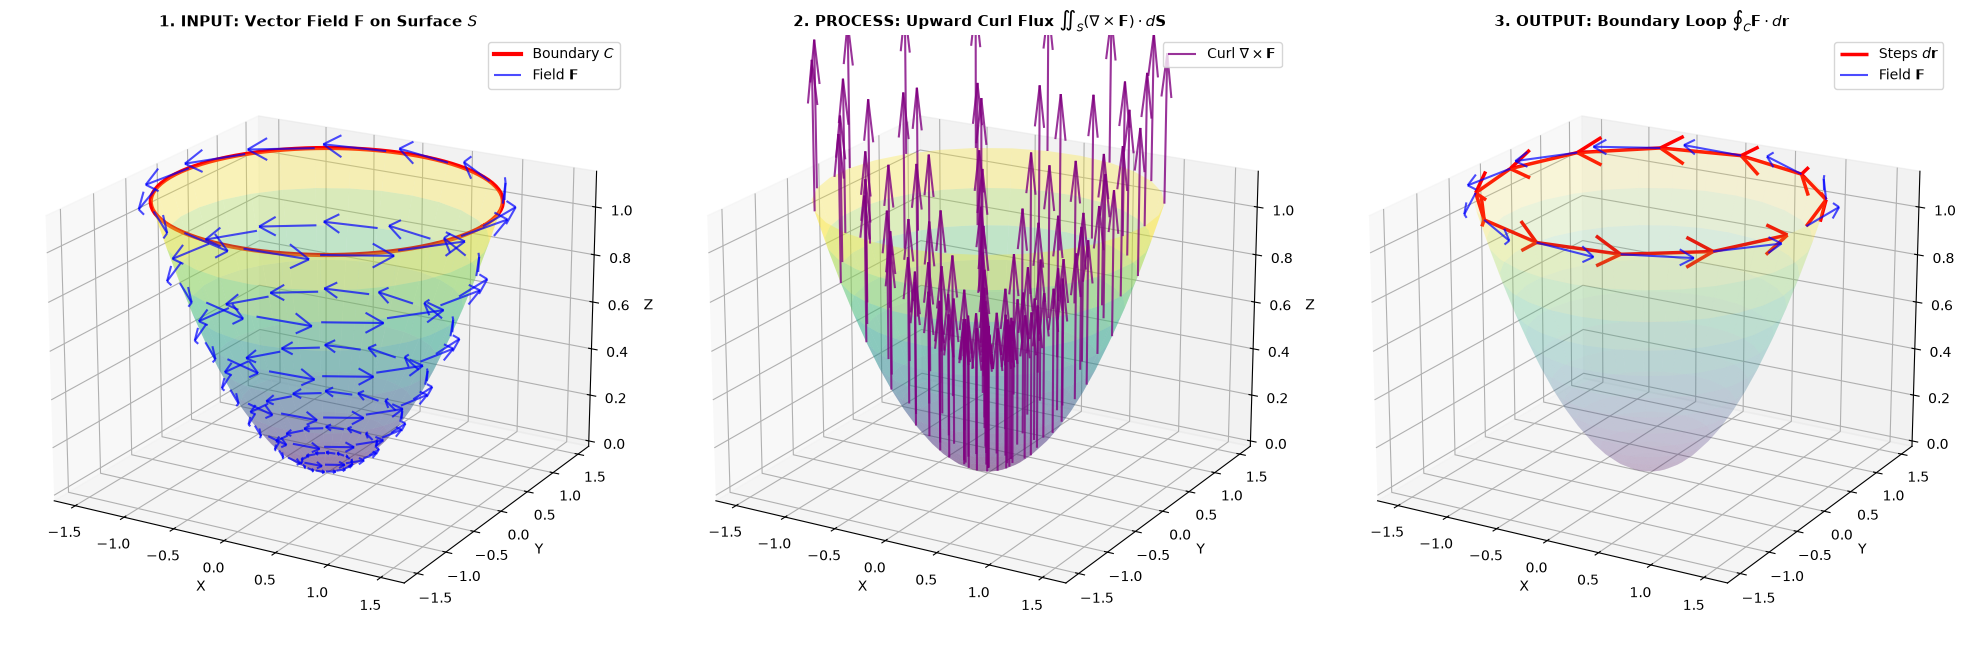

In [49]:
# Connecting Curl with Surface Integrals (Stokes' Theorem)

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Setup grid for a 3D bowl-shaped surface S (Paraboloid)
r_vals = np.linspace(0, 1.5, 15)
theta_vals = np.linspace(0, 2*np.pi, 30)
R, Theta = np.meshgrid(r_vals, theta_vals)

X = R * np.cos(Theta)
Y = R * np.sin(Theta)
Z = 0.5 * (X**2 + Y**2)  # Bowl shape

# 2. Define a swirling 3D vector field F(x, y, z) = (-y, x, 0)
# This field has a constant Curl of (0, 0, 2)
U = -Y
V = X
W = np.zeros_like(Z)

# Curl of F is constant: Curl_F = (0, 0, 2)
Curl_U = np.zeros_like(X)
Curl_V = np.zeros_like(Y)
Curl_W = 2.0 * np.ones_like(Z)

# 3. Setup the boundary curve C at the rim (R = 1.5)
t_boundary = np.linspace(0, 2*np.pi, 100)
c_x = 1.5 * np.cos(t_boundary)
c_y = 1.5 * np.sin(t_boundary)
c_z = 0.5 * (1.5**2) * np.ones_like(t_boundary)

# Calculate boundary tangents dr and field vectors along the boundary
dt = t_boundary[1] - t_boundary[0]
dcx_dt = -1.5 * np.sin(t_boundary)
dcy_dt = 1.5 * np.cos(t_boundary)
dcz_dt = np.zeros_like(t_boundary)

# Field along boundary
fc_x = -c_y
fc_y = c_x
fc_z = np.zeros_like(c_z)

# Integrand F . dr
integrand = fc_x * dcx_dt + fc_y * dcy_dt + fc_z * dcz_dt
trapezoid_func = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
if trapezoid_func is not None:
    boundary_integral = trapezoid_func(integrand, t_boundary)
else:
    boundary_integral = np.sum((integrand[:-1] + integrand[1:]) / 2.0) * dt

print("--- VERIFYING STOKES' THEOREM ---")
print(f"Boundary Line Integral ∢ F · dr: {boundary_integral:.6f}")
# For constant Curl=(0,0,2) and flat projection area of pi * R^2
print(f"Surface Integral of Curl ∬ (∇×F) · dS: {2.0 * np.pi * (1.5**2):.6f}")
print("---------------------------------")

# 4. Plot the results
fig = plt.figure(figsize=(20, 6.5))

# --- Panel 1: INPUT (Vector Field on Surface) ---
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
ax1.plot_surface(X, Y, Z, cmap='viridis', alpha=0.3, edgecolor='none')
ax1.plot(c_x, c_y, c_z, 'r-', linewidth=3, label='Boundary $C$')
ax1.quiver(X[::2, ::2], Y[::2, ::2], Z[::2, ::2],
          U[::2, ::2], V[::2, ::2], W[::2, ::2],
          length=0.4, color='blue', alpha=0.7, label='Field $\\mathbf{F}$')
ax1.set_title('1. INPUT: Vector Field $\\mathbf{F}$ on Surface $S$', fontsize=11, fontweight='bold')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.view_init(elev=20, azim=-60)
ax1.legend()

# --- Panel 2: PROCESS (Curl Flux through Surface) ---
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='viridis', alpha=0.3, edgecolor='none')
# Plot Curl vectors pointing upwards normal to the boundary elements
ax2.quiver(X[::2, ::2], Y[::2, ::2], Z[::2, ::2],
          Curl_U[::2, ::2], Curl_V[::2, ::2], Curl_W[::2, ::2],
          length=0.3, color='purple', alpha=0.8, label='Curl $\\nabla \\times \\mathbf{F}$')
ax2.set_title('2. PROCESS: Upward Curl Flux $\\iint_S (\\nabla \\times \\mathbf{F}) \\cdot d\\mathbf{S}$', fontsize=11, fontweight='bold')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')
ax2.view_init(elev=20, azim=-60)
ax2.legend()

# --- Panel 3: OUTPUT (Boundary Line Integral Verification) ---
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
ax3.plot_surface(X, Y, Z, cmap='viridis', alpha=0.15, edgecolor='none')

# Plot discrete displacement steps along the boundary rim
step_idx = 8
c_coarse_x = c_x[::step_idx]
c_coarse_y = c_y[::step_idx]
c_coarse_z = c_z[::step_idx]

dcx = np.diff(c_coarse_x)
dcy = np.diff(c_coarse_y)
dcz = np.diff(c_coarse_z)

# Displacement vectors d_r
ax3.quiver(c_coarse_x[:-1], c_coarse_y[:-1], c_coarse_z[:-1],
          dcx, dcy, dcz,
          color='red', arrow_length_ratio=0.3, linewidth=2.5, label='Steps $d\\mathbf{r}$')

# Field vectors evaluated along the rim
ax3.quiver(c_coarse_x[:-1], c_coarse_y[:-1], c_coarse_z[:-1],
          -c_coarse_y[:-1]*0.4, c_coarse_x[:-1]*0.4, np.zeros_like(dcx),
          color='blue', arrow_length_ratio=0.2, linewidth=1.5, alpha=0.7, label='Field $\\mathbf{F}$')

ax3.set_title('3. OUTPUT: Boundary Loop $\\oint_C \\mathbf{F} \\cdot d\\mathbf{r}$', fontsize=11, fontweight='bold')
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
ax3.set_zlabel('Z')
ax3.view_init(elev=20, azim=-60)
ax3.legend()

plt.tight_layout()
plt.show()

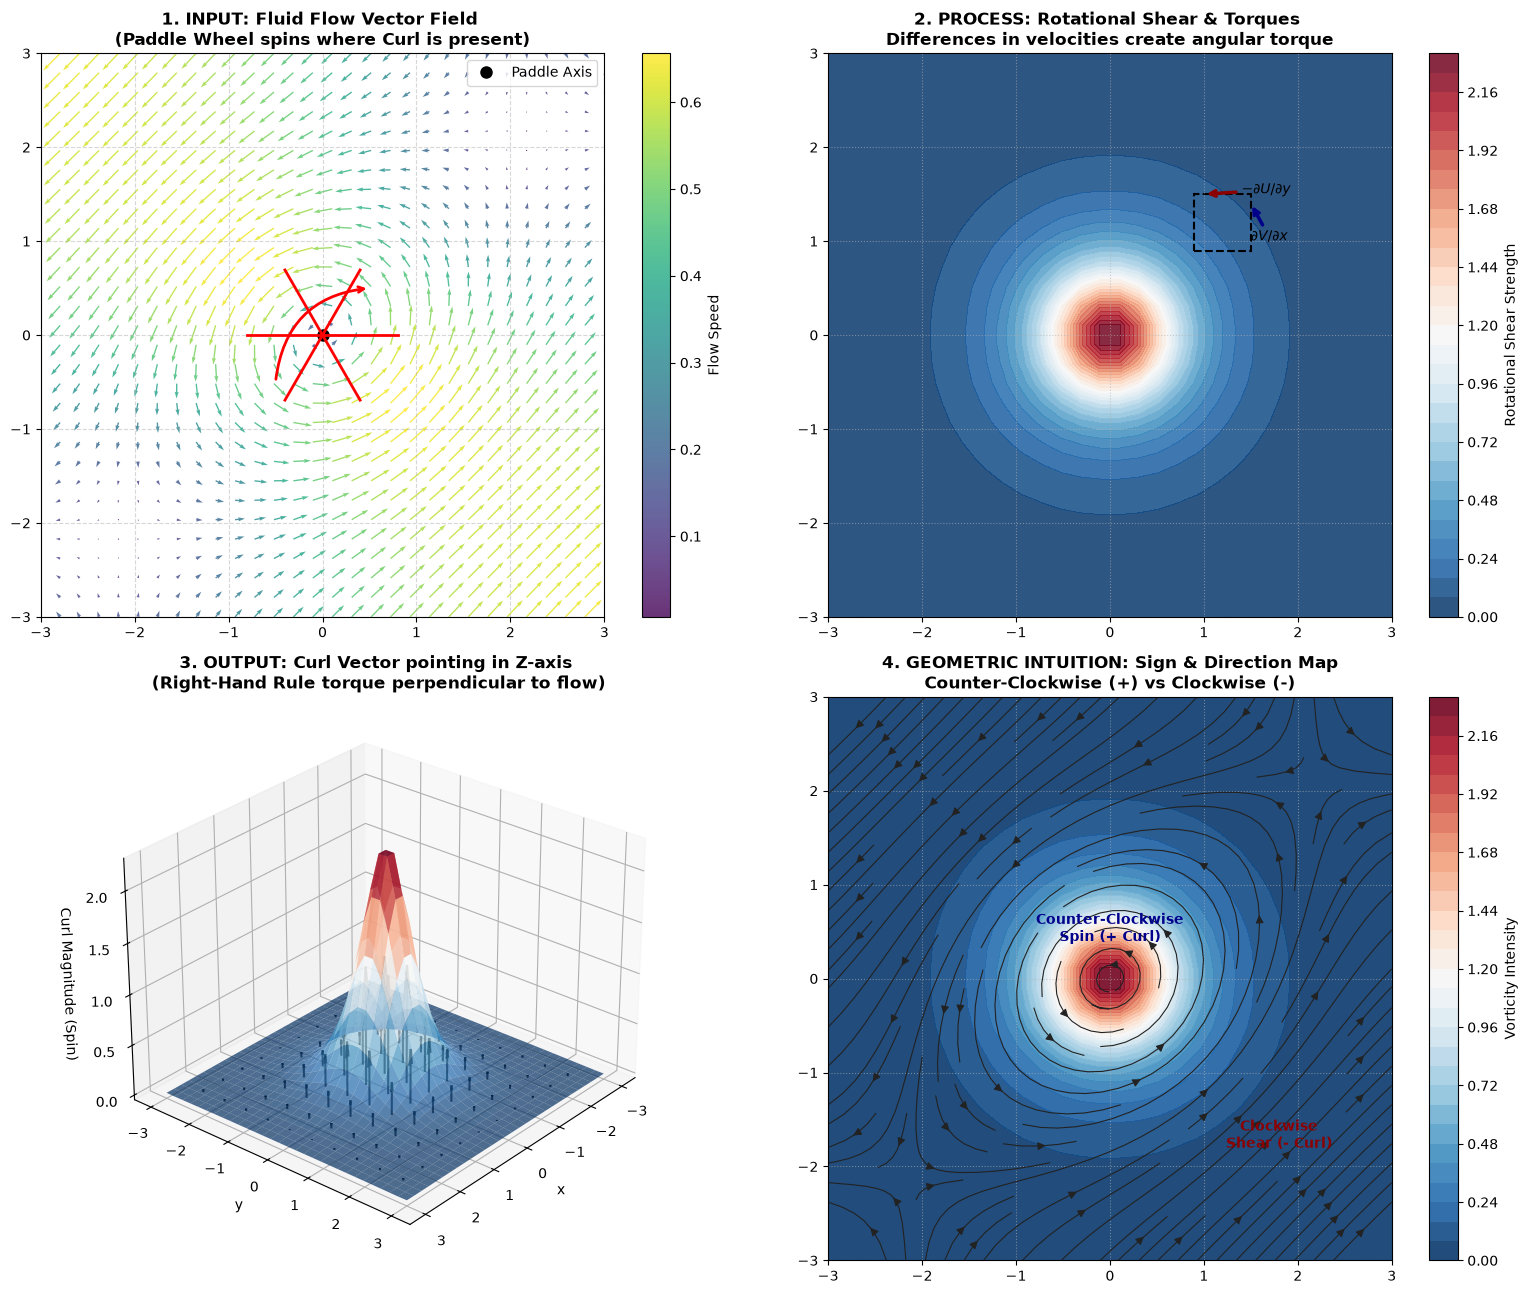

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Patch, FancyArrowPatch
from matplotlib.colors import Normalize

# 1. Setup high-quality grid
x = np.linspace(-3, 3, 30)
y = np.linspace(-3, 3, 30)
X, Y = np.meshgrid(x, y)

# 2. Define a combined vector field containing both a Vortex (CCW) and a Shear Flow (CW)
# This provides a rich palette to demonstrate both positive and negative Curl!
U = -Y / (X**2 + Y**2 + 0.8) + 0.1 * X
V = X / (X**2 + Y**2 + 0.8) - 0.1 * Y

# 3. Compute Curl components
dU_dy, dU_dx = np.gradient(U, y, x)
dV_dy, dV_dx = np.gradient(V, y, x)
curl_scalar = dV_dx - dU_dy

# Create a polished 2x2 layout illustrating: Input -> Process -> Output -> Intuition
fig = plt.figure(figsize=(16, 13))
colormap = plt.cm.RdBu_r

# --- Panel 1: INPUT (Vector Field with a Schematic Paddle Wheel) ---
ax1 = fig.add_subplot(2, 2, 1)
magnitude = np.hypot(U, V)
quiv = ax1.quiver(X, Y, U, V, magnitude, cmap='viridis', scale=15, alpha=0.8)
fig.colorbar(quiv, ax=ax1, label='Flow Speed')

# Draw a schematic paddle wheel to explain the physical test of curl
wheel_center = (0.0, 0.0)
ax1.plot(wheel_center[0], wheel_center[1], 'ko', markersize=8, label='Paddle Axis')
for angle in np.linspace(0, 2*np.pi, 6, endpoint=False):
    ax1.plot([wheel_center[0], wheel_center[0] + 0.8*np.cos(angle)],
             [wheel_center[1], wheel_center[1] + 0.8*np.sin(angle)],
             color='red', linewidth=2, zorder=5)
# Circular arrow representing rotation
ax1.annotate('', xy=(0.5, 0.5), xytext=(-0.5, -0.5),
             arrowprops=dict(arrowstyle="->", color="red", lw=2, connectionstyle="arc3,rad=-0.4"))

ax1.legend(loc='upper right')
ax1.set_title('1. INPUT: Fluid Flow Vector Field \n(Paddle Wheel spins where Curl is present)', fontsize=12, fontweight='bold')
ax1.set_xlim(-3, 3)
ax1.set_ylim(-3, 3)
ax1.set_aspect('equal')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Panel 2: PROCESS (Velocity Shear Gradient Interaction) ---
ax2 = fig.add_subplot(2, 2, 2)
# Show dV/dx - dU/dy contour gradient
contour_process = ax2.contourf(X, Y, curl_scalar, levels=30, cmap='RdBu_r', alpha=0.85)
fig.colorbar(contour_process, ax=ax2, label='Rotational Shear Strength')

# Overlay schematic differential rotation components
# Draw a microscopic fluid parcel at (1.5, 1.5)
parcel_x, parcel_y = 1.2, 1.2
ax2.add_patch(plt.Rectangle((parcel_x-0.3, parcel_y-0.3), 0.6, 0.6, fill=False, edgecolor='black', lw=1.5, ls='--'))
ax2.annotate('$\\partial V / \\partial x$', xy=(parcel_x+0.3, parcel_y+0.2), xytext=(parcel_x+0.3, parcel_y-0.2),
             arrowprops=dict(arrowstyle="->", color='darkblue', lw=2.5))
ax2.annotate('$-\\partial U / \\partial y$', xy=(parcel_x-0.2, parcel_y+0.3), xytext=(parcel_x+0.2, parcel_y+0.3),
             arrowprops=dict(arrowstyle="->", color='darkred', lw=2.5))

ax2.set_title('2. PROCESS: Rotational Shear & Torques \nDifferences in velocities create angular torque', fontsize=12, fontweight='bold')
ax2.set_xlim(-3, 3)
ax2.set_ylim(-3, 3)
ax2.set_aspect('equal')
ax2.grid(True, linestyle=':', alpha=0.6)

# --- Panel 3: OUTPUT (3D Torque Vector Axis) ---
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
surf = ax3.plot_surface(X, Y, curl_scalar, cmap='RdBu_r', edgecolor='none', alpha=0.7)

# Plot actual vertical curl torque vectors at coarser points
x_coarse = np.linspace(-2.5, 2.5, 10)
y_coarse = np.linspace(-2.5, 2.5, 10)
X_c, Y_c = np.meshgrid(x_coarse, y_coarse)
R2_c = X_c**2 + Y_c**2 + 0.8
U_c = -Y_c / R2_c + 0.1 * X_c
V_c = X_c / R2_c - 0.1 * Y_c
dU_dy_c, dU_dx_c = np.gradient(U_c, y_coarse, x_coarse)
dV_dy_c, dV_dx_c = np.gradient(V_c, y_coarse, x_coarse)
curl_z = dV_dx_c - dU_dy_c

# 3D Vector arrows representing Curl pointing upwards/downwards (z-axis)
ax3.quiver(X_c.flatten(), Y_c.flatten(), np.zeros_like(X_c).flatten(),
           np.zeros_like(X_c).flatten(), np.zeros_like(Y_c).flatten(), curl_z.flatten(),
           length=0.8, color='black', alpha=0.8, arrow_length_ratio=0.3)

ax3.set_title('3. OUTPUT: Curl Vector pointing in Z-axis \n(Right-Hand Rule torque perpendicular to flow)', fontsize=12, fontweight='bold')
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_zlabel('Curl Magnitude (Spin)')
ax3.view_init(elev=28, azim=40)

# --- Panel 4: GEOMETRIC INTUITION (Vorticity Direction Map) ---
ax4 = fig.add_subplot(2, 2, 4)
contour_int = ax4.contourf(X, Y, curl_scalar, levels=30, cmap='RdBu_r', alpha=0.9)
fig.colorbar(contour_int, ax=ax4, label='Vorticity Intensity')

# Overlay streamline traces to show actual flow trajectory relative to curl centers
ax4.streamplot(X, Y, U, V, color='#222222', density=1.0, linewidth=0.8, arrowsize=1.2)

# Explicit annotations for Rotation signs
ax4.text(0.0, 0.4, "Counter-Clockwise\nSpin (+ Curl)", color="darkblue", weight="bold", fontsize=10, ha="center")
ax4.text(1.8, -1.8, "Clockwise\nShear (- Curl)", color="darkred", weight="bold", fontsize=10, ha="center")

ax4.set_title('4. GEOMETRIC INTUITION: Sign & Direction Map\nCounter-Clockwise (+) vs Clockwise (-)', fontsize=12, fontweight='bold')
ax4.set_xlim(-3, 3)
ax4.set_ylim(-3, 3)
ax4.set_aspect('equal')
ax4.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [51]:
import numpy as np

# 1. Physical and Numerical Parameters
L = 10.0          # Length of the metal rod
T_max = 4.0       # Total simulation time
alpha = 1.2       # Thermal diffusivity coefficient

Nx = 80           # Number of spatial grid points
Nt = 500          # Number of time steps

dx = L / (Nx - 1)
dt = T_max / Nt

# Check stability condition for FTCS scheme (r <= 0.5)
r = alpha * dt / (dx**2)
if r > 0.5:
    print(f"Warning: The simulation might be unstable. r = {r:.4f} (should be <= 0.5). Adjusting dt...")
    dt = 0.5 * (dx**2) / alpha
    Nt = int(np.ceil(T_max / dt))
    r = alpha * dt / (dx**2)
    print(f"New time step size: {dt:.6f}, Total steps: {Nt}, r = {r:.4f}")

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

# 2. Initialize temperature grid U(x, t)
U = np.zeros((Nx, Nt))

# Initial Condition: A highly localized hot spot (Gaussian peak) in the middle
U[:, 0] = 100.0 * np.exp(-((x_grid - L/2)**2) / 1.5)

# Boundary Conditions (Dirichlet): Ends of the rod are kept in contact with ice (0 degrees)
U[0, :] = 0.0
U[-1, :] = 0.0

# 3. Finite Difference Solver (FTCS)
for t in range(0, Nt - 1):
    for i in range(1, Nx - 1):
        U[i, t+1] = U[i, t] + r * (U[i+1, t] - 2*U[i, t] + U[i-1, t])

print("Heat transfer equation solved successfully!")

implU = U.copy()

New time step size: 0.006676, Total steps: 600, r = 0.5000
Heat transfer equation solved successfully!


$$\frac{\partial U}{\partial t} = \alpha \frac{\partial^2 U}{\partial x^2}$$

In [52]:
import time
import numpy as np
import sympy as sp
from scipy.integrate import quad
from IPython.display import Math, display

t0 = time.perf_counter()

# 1. Physical and Numerical Parameters
L = 10.0        # Length of the metal rod
T_max = 4.0     # Total simulation time
alpha = 1.2     # Thermal diffusivity coefficient

Nx = 80         # Number of spatial grid points
Nt = 500        # Number of time steps

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

# 2. Fast Symbolic Separation of Variables (SymPy)
x, t, k = sp.symbols("x t k", positive=True)
n = sp.Symbol("n", integer=True, positive=True)

L_sym = sp.Rational(10)
alpha_sym = sp.Rational(6, 5)

U_sym = sp.Function("U")(x, t)
X = sp.Function("X")(x)
T = sp.Function("T")(t)

heat_eq = sp.Eq(U_sym.diff(t), alpha_sym * U_sym.diff(x, 2))
sep_x, sep_t = sp.pde_separate(heat_eq, U_sym, [X, T], strategy="mul")

sol_X = sp.dsolve(sp.Eq(sep_x, -k**2), X)
sol_T = sp.dsolve(sp.Eq(sep_t, -k**2), T)

k_n_sym = n * sp.pi / L_sym
B_n_sym = sp.IndexedBase("B")
sol_U_general = sp.Eq(
    U_sym,
    sp.Sum(B_n_sym[n] * sp.sin(k_n_sym * x) * sp.exp(-alpha_sym * k_n_sym**2 * t), (n, 1, sp.oo))
)

# 3. Fast Numerical Fourier Coefficients (Odd modes only by symmetry)
u0_func = lambda x_val: 100.0 * np.exp(-((x_val - L / 2.0) ** 2) / 1.5)

odd_modes = np.arange(1, 36, 2)  # 1, 3, 5, ..., 35
kn_vals = odd_modes * np.pi / L
Bn_vals = np.array([
    (2.0 / L) * quad(lambda xv: u0_func(xv) * np.sin(kn * xv), 0.0, L)[0]
    for kn in kn_vals
])

# Build clean 4-term LaTeX expression for display
U_display_terms = [
    sp.Float(Bn_vals[i], 6) * sp.sin(int(odd_modes[i]) * sp.pi * x / L_sym) * sp.exp(-alpha_sym * (int(odd_modes[i]) * sp.pi / L_sym)**2 * t)
    for i in range(4)
]
U_display_latex = sp.latex(sum(U_display_terms)) + r" + \cdots"

# 4. Print & Render LaTeX Equations
print("--- Raw LaTeX Strings ---")
print("Spatial X(x) :", sp.latex(sol_X))
print("Temporal T(t):", sp.latex(sol_T))
print("General U    :", sp.latex(sol_U_general))
print("Evaluated U  :", f"U{{\\left(x,t \\right)}} = {U_display_latex}\n")

display(Math(r"\textbf{Spatial Solution: } " + sp.latex(sol_X)))
display(Math(r"\textbf{Temporal Solution: } " + sp.latex(sol_T)))
display(Math(r"\textbf{General } U(x,t)\textbf{: } " + sp.latex(sol_U_general)))
display(Math(r"\textbf{Evaluated } U(x,t)\textbf{: } U{\left(x,t \right)} = " + U_display_latex))

# 5. Vectorized Matrix Evaluation U(x, t) via BLAS Matrix Multiplication
sin_matrix = np.sin(np.outer(x_grid, kn_vals))               # Shape: (Nx, M)
exp_matrix = np.exp(-alpha * np.outer(kn_vals**2, t_grid))   # Shape: (M, Nt)

U = (sin_matrix * Bn_vals) @ exp_matrix                      # Shape: (Nx, Nt)
U[0, :] = 0.0
U[-1, :] = 0.0

exactU = U.copy()

elapsed_ms = (time.perf_counter() - t0) * 1000
print(f"Solved in {elapsed_ms:.1f} ms | U shape: {U.shape} | Initial peak: {U[:, 0].max():.4f} °C | Final peak: {U[:, -1].max():.4f} °C")




--- Raw LaTeX Strings ---
Spatial X(x) : X{\left(x \right)} = C_{1} \sin{\left(k x \right)} + C_{2} \cos{\left(k x \right)}
Temporal T(t): T{\left(t \right)} = C_{1} e^{- \frac{6 k^{2} t}{5}}
General U    : U{\left(x,t \right)} = \sum_{n=1}^{\infty} e^{- \frac{3 \pi^{2} n^{2} t}{250}} \sin{\left(\frac{\pi n x}{10} \right)} {B}_{n}
Evaluated U  : U{\left(x,t \right)} = 17.2111 e^{- \frac{3 \pi^{2} t}{10}} \sin{\left(\frac{\pi x}{2} \right)} + 41.8386 e^{- \frac{3 \pi^{2} t}{250}} \sin{\left(\frac{\pi x}{10} \right)} - 31.1163 e^{- \frac{27 \pi^{2} t}{250}} \sin{\left(\frac{3 \pi x}{10} \right)} - 7.08011 e^{- \frac{147 \pi^{2} t}{250}} \sin{\left(\frac{7 \pi x}{10} \right)} + \cdots



<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Solved in 103.2 ms | U shape: (80, 500) | Initial peak: 99.7333 °C | Final peak: 26.4836 °C


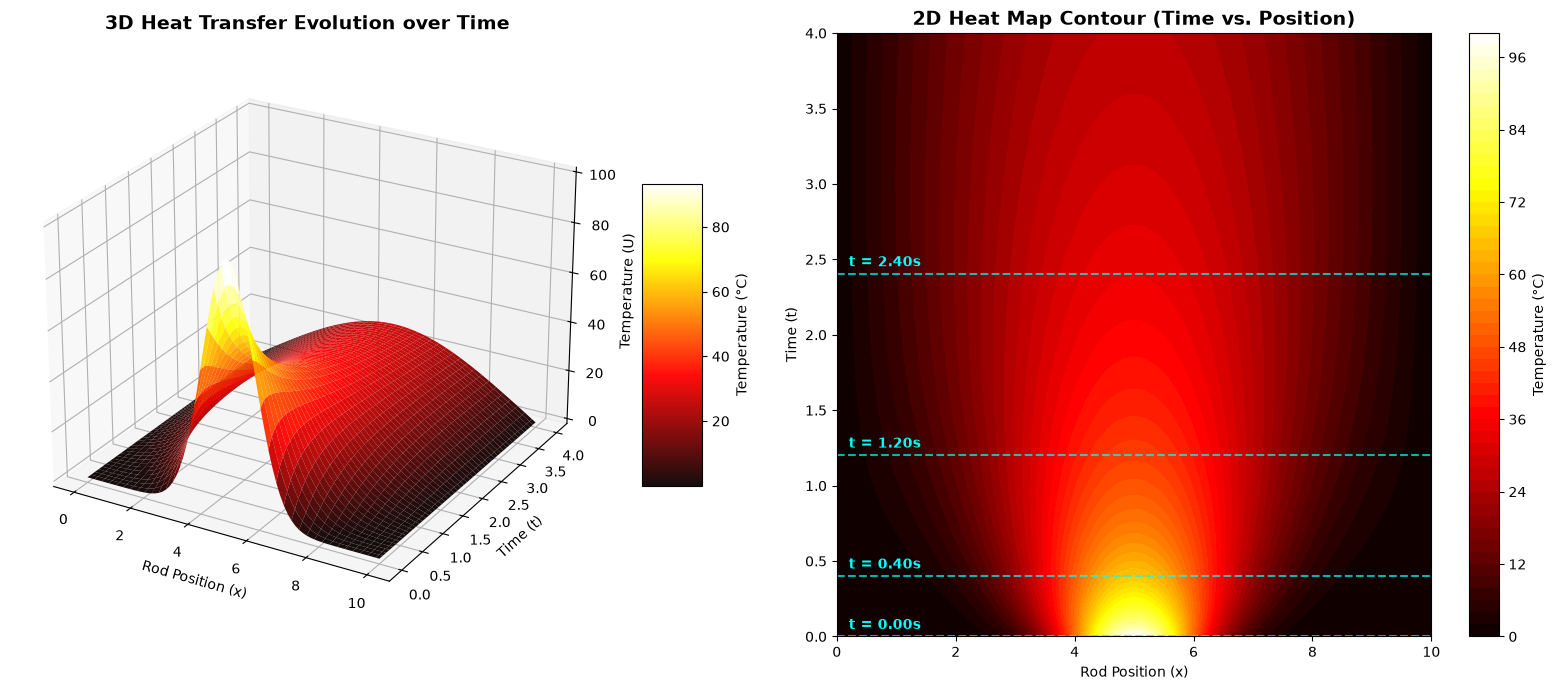

In [53]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create Spatiotemporal Grids for plotting
X_mesh, T_mesh = np.meshgrid(x_grid, t_grid)
U_plot = U.T  # Transpose to match dimensions (time steps x spatial steps)

fig = plt.figure(figsize=(16, 7))

# --- Left Panel: 3D Heat Diffusion Surface Map ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X_mesh, T_mesh, U_plot, cmap='hot', edgecolor='none', alpha=0.95)
fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=5, label='Temperature (°C)')
ax1.set_title('3D Heat Transfer Evolution over Time', fontsize=14, fontweight='bold')
ax1.set_xlabel('Rod Position (x)')
ax1.set_ylabel('Time (t)')
ax1.set_zlabel('Temperature (U)')
ax1.view_init(elev=25, azim=-60)

# --- Right Panel: 2D Spatial-Temporal Temperature Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X_mesh, T_mesh, U_plot, levels=50, cmap='hot')
fig.colorbar(contour, ax=ax2, label='Temperature (°C)')

# Highlight some specific time slices as lines
time_snapshots = [0, int(Nt*0.1), int(Nt*0.3), int(Nt*0.6)]
for step in time_snapshots:
    ax2.axhline(y=t_grid[step], color='cyan', linestyle='--', alpha=0.7)
    ax2.text(0.2, t_grid[step] + 0.05, f't = {t_grid[step]:.2f}s', color='cyan', fontsize=10, weight='bold')

ax2.set_title('2D Heat Map Contour (Time vs. Position)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Rod Position (x)')
ax2.set_ylabel('Time (t)')

plt.tight_layout()
plt.show()

In [54]:
import time
import numpy as np
from scipy.linalg import solve_banded

# 1. Physical and Numerical Parameters
L = 10.0        # Length of the metal rod
T_max = 4.0     # Total simulation time
alpha = 1.2     # Thermal diffusivity coefficient

Nx = 80         # Number of spatial grid points
Nt = 500        # Number of time steps (can now be much smaller!)

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

dx = x_grid[1] - x_grid[0]
dt = t_grid[1] - t_grid[0]
r = alpha * dt / (dx**2)

print(f"Implicit Solver -> dt: {dt:.6f}, Nt: {Nt}, Fourier number r: {r:.4f} (No stability limit!)")

# 2. Initialize temperature grid U(x, t)
U = np.zeros((Nx, Nt))
U[:, 0] = 100.0 * np.exp(-((x_grid - L/2)**2) / 1.5)
U[0, :] = 0.0
U[-1, :] = 0.0

# 3. Assemble Tridiagonal Matrix in Banded Format (3 diagonals x M interior nodes)
M = Nx - 2  # Number of interior unknowns
ab = np.zeros((3, M))
ab[0, 1:] = -r          # Upper diagonal
ab[1, :]  = 1.0 + 2*r   # Main diagonal
ab[2, :-1] = -r         # Lower diagonal

# 4. Implicit Time-Stepping Loop (Thomas Algorithm via LAPACK)
start = time.perf_counter()
for t in range(Nt - 1):
    # Right-hand side is simply the interior temperature at step t
    rhs = U[1:-1, t]
    U[1:-1, t+1] = solve_banded((1, 1), ab, rhs)

elapsed = (time.perf_counter() - start) * 1000
print(f"Solved in {elapsed:.2f} ms | Max final temp: {U[:, -1].max():.4f} °C")

explU = U.copy()


Implicit Solver -> dt: 0.008016, Nt: 500, Fourier number r: 0.6003 (No stability limit!)
Solved in 12.51 ms | Max final temp: 26.5013 °C


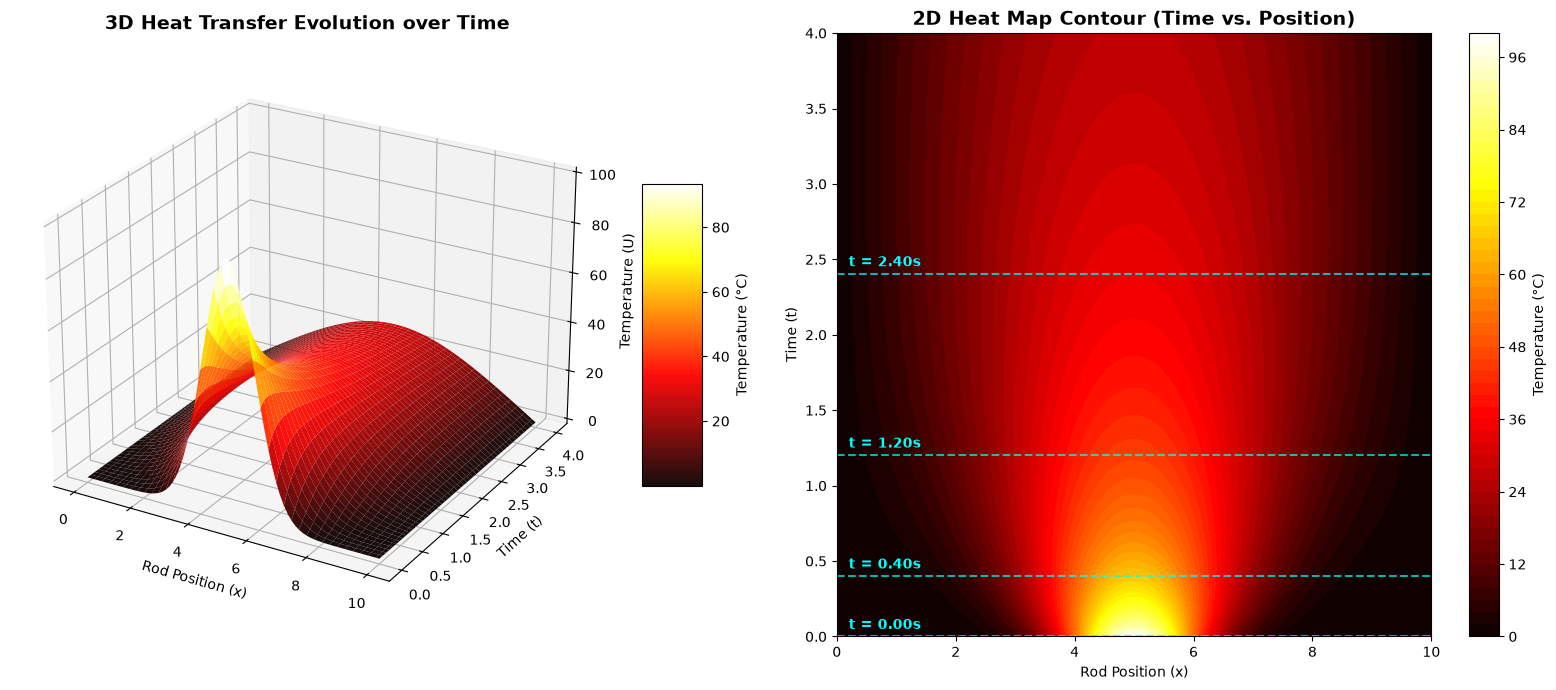

In [55]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create Spatiotemporal Grids for plotting
X_mesh, T_mesh = np.meshgrid(x_grid, t_grid)
U_plot = U.T  # Transpose to match dimensions (time steps x spatial steps)

fig = plt.figure(figsize=(16, 7))

# --- Left Panel: 3D Heat Diffusion Surface Map ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X_mesh, T_mesh, U_plot, cmap='hot', edgecolor='none', alpha=0.95)
fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=5, label='Temperature (°C)')
ax1.set_title('3D Heat Transfer Evolution over Time', fontsize=14, fontweight='bold')
ax1.set_xlabel('Rod Position (x)')
ax1.set_ylabel('Time (t)')
ax1.set_zlabel('Temperature (U)')
ax1.view_init(elev=25, azim=-60)

# --- Right Panel: 2D Spatial-Temporal Temperature Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X_mesh, T_mesh, U_plot, levels=50, cmap='hot')
fig.colorbar(contour, ax=ax2, label='Temperature (°C)')

# Highlight some specific time slices as lines
time_snapshots = [0, int(Nt*0.1), int(Nt*0.3), int(Nt*0.6)]
for step in time_snapshots:
    ax2.axhline(y=t_grid[step], color='cyan', linestyle='--', alpha=0.7)
    ax2.text(0.2, t_grid[step] + 0.05, f't = {t_grid[step]:.2f}s', color='cyan', fontsize=10, weight='bold')

ax2.set_title('2D Heat Map Contour (Time vs. Position)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Rod Position (x)')
ax2.set_ylabel('Time (t)')

plt.tight_layout()
plt.show()

In [56]:
# Fix the swapped labels first:
# explU = explicit result (80, 600), implU = implicit result (80, 500)

diff_final = explU[:, -1] - implU[:, -1]
print("Max difference at t = 4.0s:", np.max(np.abs(diff_final)))


Max difference at t = 4.0s: 0.022182616933172028
